# Quick start: LISST-200X

`lisst_200X` reads a LISST-200X `.RBN` file and returns an {py:class}`xarray.Dataset` with the
near-forward VSF measured by the 36 ring detectors and the beam attenuation coefficient.

The example is the same *Lingulodinium polyedra* culture as in {doc}`quickstart_lisst_vsf`.

> **Note:** the data files used here are not distributed with the package. Set `datadir` to the location of your own files to run this notebook. In the documentation, the notebook is rendered with its saved outputs.

In [1]:
import os
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pylisst import lisst_200X

warnings.filterwarnings('ignore')
opj = os.path.join

datadir = '/DATA/projet/gernez/hablab/lisst200/raw/2022'
ds = lisst_200X(opj(datadir, 'lin_c1_r1_s_20220421.rbn'))
ds

<xarray.Dataset>
Dimensions:      (set: 28, scat_ang: 36)
Coordinates:
  * set          (set) int64 0 1 2 3 4 5 6 7 8 9 ... 19 20 21 22 23 24 25 26 27
    ring         (scat_ang) int64 0 1 2 3 4 5 6 7 8 ... 28 29 30 31 32 33 34 35
  * scat_ang     (scat_ang) float64 0.03966 0.0468 0.05522 ... 9.309 10.97 12.92
Data variables:
    vsf          (set, scat_ang) float64 0.0034 0.0009442 ... 2.974e-07
    c_att        (set) float64 7.605 7.896 8.03 8.11 ... 6.484 6.152 6.382 6.026
    datetime     (set) datetime64[ns] 2022-04-21T08:58:22 ... 2022-04-21T08:5...
    depth        (set) float64 8.75 8.74 8.75 8.76 8.75 ... 8.75 8.75 8.75 8.77
    temperature  (set) float64 21.6 21.6 21.6 21.6 ... 21.63 21.64 21.64 21.64
Attributes: (12/24)
    name:             LISST-200X 2094
\n 
:
    serialNumber:     2094
    firmwareVer:      1.415
    VCC:              36721
    fullPath:         0.025
    effPath:          0.025
    ...               ...
    burstInterval:    0
    transmitRaw:      1
    lifetimeSamples:  511498
    lifetimeLaserOn:  780158
    supportBoard:     0
    ambientLight:     1

The dataset contains, for each measurement `set`:

| Variable      | Description                                                 |
|---------------|-------------------------------------------------------------|
| `vsf`         | VSF at the ring center angles `scat_ang` (degrees, in water) |
| `c_att`       | Beam attenuation coefficient (m$^{-1}$)                     |
| `datetime`    | Time of the measurement                                     |
| `depth`       | Depth (m)                                                   |
| `temperature` | Temperature (degrees Celsius)                               |

The instrument configuration (serial number, firmware, optical path, ...) is stored in the
attributes.

```{warning}
The radiometric calibration of the laser reference of the LISST-200X is unknown, so the
magnitude of `vsf` is not calibrated: only its angular shape is meaningful.
```

serial number: 2094 | optical path: 0.025 m


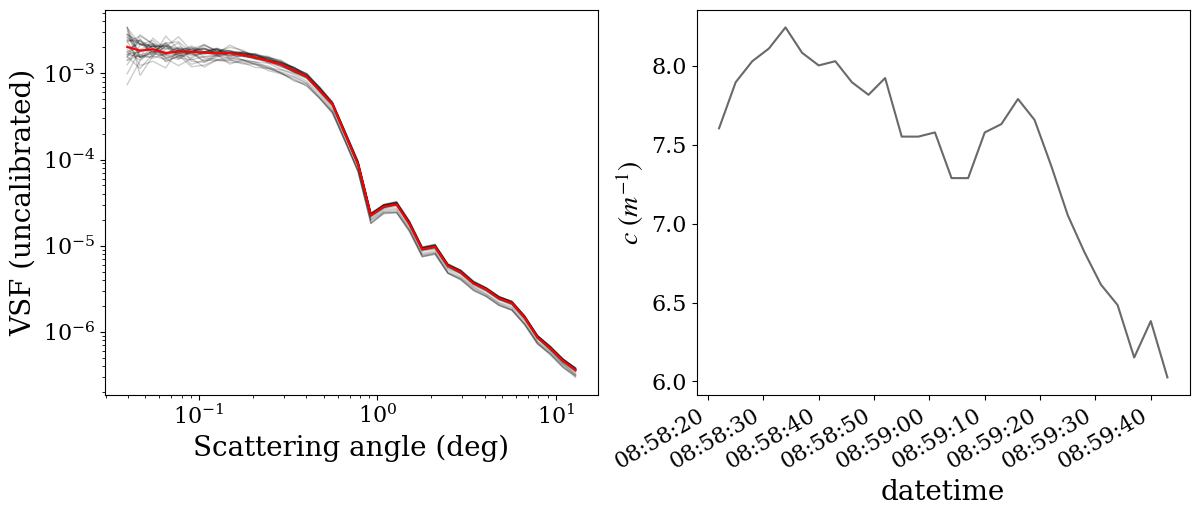

In [2]:
print('serial number:', ds.attrs['serialNumber'], '| optical path: {} m'.format(ds.attrs['effPath']))

fig, axs = plt.subplots(ncols=2, figsize=(14, 5))
ds.vsf.plot(hue='set', color='black', alpha=0.2, lw=1, add_legend=False, ax=axs[0])
ds.vsf.median('set').plot(color='red', lw=1.5, ax=axs[0])
axs[0].loglog()
axs[0].set_xlabel('Scattering angle (deg)')
axs[0].set_ylabel('VSF (uncalibrated)')

ds.set_coords('datetime').c_att.plot(x='datetime', ax=axs[1])
axs[1].set_ylabel('$c\\ (m^{-1})$')
plt.show()